In [1]:
import pandas as pd
from pandas import DataFrame  as df

#데이터 불러오기 시간이랑 트윗 텍스트만
Data = pd.read_csv("노년층이 많이 대출한 책(csv).csv")

Data

,검색어,저자,책소개
0,황금종이,조정래,"""말도 마. 돈에 얽힌 일이라면 무슨 일이든지 다 일어나.”\n“큰돈 앞에서는 큰 ..."
1,풍수전쟁,김진명,그의 입에서 여태까지의 목소리가 아니라 남자도 여자도 아닌 마치 다른 세상의 것인 ...
2,아버지의 해방일지,정지아,아버지가 죽었다. 전봇대에 머리를 박고. 평생을 정색하고 살아온 아버지가 전봇대에 ...
3,퓨처 셀프,벤저민 하디,미래의 나와 연결되는 수준이 현재의 삶과 행동의 수준을 결정한다. 연구 결과가 명확...
4,천년의 질문,조정래,장우진은 고석민의 말꼬리에서 문득 물기를 느꼈다. 생활 여건에 무슨 어려움이 생긴 ...
5,너는 다시 외로워질 것이다,공지영,"사랑하는 나의 벗들, 그분께서 나를 산과 바다로 인도하시고 고통의 낚싯바늘에 나를 ..."
6,불편한 편의점,김호연,“근데 이게 마지막 술이에요. 이거 먹고 술 끊는 조건으로 우리 가게 일 좀 봐줘요...
7,작별하지 않는다,한강,생명이 얼마나 약한 것인지 그때 실감했다. 저 살과 장기와 뼈와 목숨 들이 얼마나 ...
8,푸틴을 죽이는 완벽한 방법,김진명,"“음, 내가 푸틴의 침공을 유발했단 건가?”\n“속마음이 어떻든 모호한 태도를 취했..."
9,당신도 느리게 나이 들 수 있습니다,정희원,만성질환은 대개 평생 동안 축적된 노화의 결과다. 한 사람의 가치관과 생활방식이 만...


In [2]:
Data.책소개 = Data.책소개.astype(str)

In [3]:
import pandas as pd
import numpy as np

# 데이터 프레임의 'text' 열의 값들을 str 형식으로 바꾸기
Data['책소개'] = Data['책소개'].astype(str)

# 한글이 아니면 빈 문자열로 바꾸기
Data['책소개'] = Data['책소개'].str.replace('[^ㄱ-ㅎㅏ-ㅣ가-힣]', ' ', regex=True)

# 빈 문자열을 NAN 값으로 바꾸기
Data['책소개'] = Data['책소개'].replace({'': np.nan})
Data['책소개'] = Data['책소개'].replace(r'^\s*$', np.nan, regex=True)

# NAN이 있는 행은 삭제
Data.dropna(subset=['책소개'], how='any', inplace=True)

# 인덱스 차곡차곡
Data = Data.reset_index(drop=True)

# 데이터 프레임에 null 값이 있는지 확인
print(Data.isnull().values.any())


False


In [4]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

        명사
0       명의
1       이건
2       선사
3       재기
4       동네
...    ...
2242    다짐
2243    천둥
2244   올린다
2245    부담
2246  밀드러드

[2247 rows x 1 columns]


In [23]:
import pandas as pd
from konlpy.tag import Okt
import gensim
from gensim.corpora import Dictionary
import re
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.append([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 사전 생성
id2word = Dictionary(data_word)

# 단어 빈도 필터링
id2word.filter_extremes(no_below=5, no_above=0.5)  # 5회 이하로 등장하는 단어와 상위 50% 단어 필터링

# 코퍼스 생성
corpus = [id2word.doc2bow(doc) for doc in data_word]

# LDA 모델 설정
num_topics = 5  # 토픽 개수 설정
lda_model = gensim.models.LdaModel(
    corpus,
    num_topics=num_topics,
    id2word=id2word,
    passes=30,
    random_state=1000,
    alpha='auto',  # alpha 파라미터 자동 설정
    eta='auto'     # eta 파라미터 자동 설정
)

# 결과를 데이터프레임으로 변환
topics = []
for idx, topic in lda_model.show_topics(formatted=False):
    topic_words = sorted(topic, key=lambda x: x[1], reverse=True)  # 비중에 따라 단어 정렬
    topic_words = [word for word, _ in topic_words]  # 단어만 추출
    topics.append((idx, ", ".join(topic_words)))

# 데이터프레임 생성
topics_df = pd.DataFrame(topics, columns=['토픽 번호', '주요 단어'])

# 데이터프레임 출력 
print(topics_df)

# 각 토픽의 상위 n개의 단어 출력
n = 10  # 상위 n개의 단어 수
for idx, topic in lda_model.show_topics(num_topics=num_topics, num_words=n, formatted=False):
    print(f"토픽 {idx + 1}:")
    topic_words = sorted(topic, key=lambda x: x[1], reverse=True)  # 비중에 따라 단어 정렬
    for word, weight in topic_words:
        print(f"{word}: {weight:.4f}")
    print("\n")



   토픽 번호                                     주요 단어
0      0    하나, 모든, 모두, 이상, 위해, 가장, 의미, 거의, 무엇, 대답
1      1   당신, 이름, 스스로, 정도, 위해, 변화, 이상, 동안, 결과, 방법
2      2   아들, 거기, 어쩌면, 학교, 여기, 그녀, 기억, 자기, 다시, 하나
3      3   인생, 인간, 자기, 하나, 대한, 경험, 그것, 가지, 가장, 이야기
4      4  모든, 얼마나, 다시, 그녀, 하늘, 그것, 목소리, 그때, 의미, 소리
토픽 1:
하나: 0.0629
모든: 0.0482
모두: 0.0420
이상: 0.0372
위해: 0.0311
가장: 0.0309
의미: 0.0293
거의: 0.0293
무엇: 0.0293
대답: 0.0293


토픽 2:
당신: 0.1821
이름: 0.0702
스스로: 0.0362
정도: 0.0361
위해: 0.0329
변화: 0.0324
이상: 0.0317
동안: 0.0305
결과: 0.0259
방법: 0.0245


토픽 3:
아들: 0.0508
거기: 0.0342
어쩌면: 0.0341
학교: 0.0300
여기: 0.0300
그녀: 0.0300
기억: 0.0300
자기: 0.0258
다시: 0.0258
하나: 0.0217


토픽 4:
인생: 0.0517
인간: 0.0396
자기: 0.0393
하나: 0.0391
대한: 0.0388
경험: 0.0362
그것: 0.0361
가지: 0.0327
가장: 0.0301
이야기: 0.0292


토픽 5:
모든: 0.0647
얼마나: 0.0372
다시: 0.0352
그녀: 0.0300
하늘: 0.0300
그것: 0.0300
목소리: 0.0300
그때: 0.0287
의미: 0.0229
소리: 0.0229




In [24]:
import pyLDAvis
import pyLDAvis.gensim_models

# pyLDAvis를 사용한 시각화
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus, id2word)
pyLDAvis.display(vis)

In [26]:
font = 'DoHyeon-Regular.ttf'

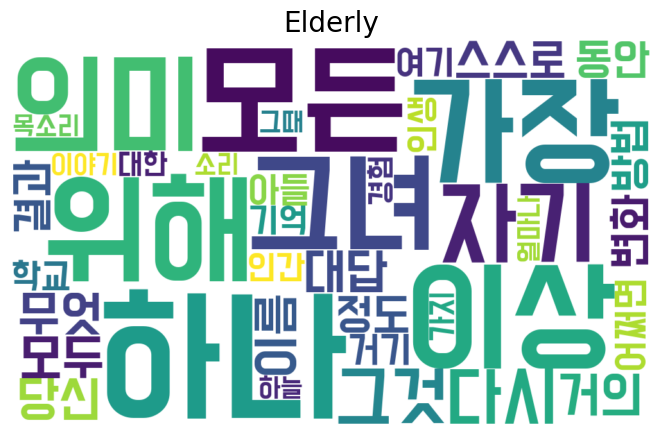

In [25]:
# 워드클라우드 생성
word_string = ", ".join(topics_df['주요 단어'].tolist())

font = 'DoHyeon-Regular.ttf'  # 한글 폰트 경로

wordcloud = WordCloud(
    font_path=font,
    width=1000,
    height=600,
    background_color='white',
    colormap='viridis',
    max_words=200,
    random_state=42
).generate(word_string)

# 워드클라우드 시각화
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Elderly', fontsize=20)
plt.show()


<노년>  
토픽 0 : 인생의 의미
토픽 1 : 성찰
토픽 2 : 추억
토픽 3 : 인생
토픽 4 : 회상